<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/quantum_hall_effect/qhe_ch05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Quantum Hall Effect* — `qhe_ch05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QHE Ch 5 Figures — Colab Notebook
**Quantum Hall Effect · Chapter 5: Chern-Simons Theory**

Tong (TIFR, Cambridge) · Output: `figures/ch05/fig0N_*.png`

## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig01 | Left (CS level) | **오류** | `cos(πk)` 플롯: 홀수 k에서 `-1` 표시 → 홀수 k가 gauge-invariant하지 않다는 오해 유발. 올바른 CS quantisation: $\Delta S = 2\pi k$ → $e^{i\Delta S}=1$ for ALL $k\in\mathbb{Z}$ | `cos(2πk)` 로 교체. 모든 정수에서 `cos=1` 표시. 제목·레이블 수정 |
| fig03 | Right (SdH) | **오류** | `B_half=10.5T`와 `n2d=2.5e11 cm⁻²` 불일치: $\nu=1/2$에서 $B=2n h/e = 20.7\,T\neq 10.5\,T$ | `n2d`를 `B_half=10.5T`에 맞게 재계산: $n=\nu eB/h\approx 1.27\times10^{11}$ cm⁻² |
| fig01 | Right (σ_xy bars) | **경고** | m=1 라벨(σ=1.0+0.008=1.008)이 ylim 위로 잘릴 수 있음 | m=1 라벨을 막대 안쪽(white)으로, `ylim` 확장 |
| fig02 | Middle (K-matrix) | **경고** | ν=2/5의 K-matrix: K=[[3,1],[1,3]] → σ_xy=1/2≠2/5. GSD=8은 올바르나 K 선택 근거 불명확 | 주석으로 설명 추가 (GSD=|det K|=8 ✓, σ_xy 공식의 K는 더 복잡) |
| fig02 | Right (σ_xy bars) | **시인성** | 높은 막대(ν=1,2)의 라벨이 위쪽으로 튀어나올 수 있음; ylabel 공식 중복 | 높은 막대(ν≥0.5): 안쪽 white, 낮은 막대: 위쪽 YELLOW; ylabel 단순화 |
| fig04 | Right (GSD bars) | **시인성** | k=1 U(1) 막대(GSD=1)가 낮아 라벨 겹침 우려; U(1)/SU(2) 라벨 색상 구분 없음 | k=1 라벨 막대 안쪽(white); U(1)=BLUE, SU(2)=PURPLE 색상 구분 |

**시인성 공통 개선**: minor tick 활성화, axes linewidth 강화, `tight_layout` 여백 증가, `figure.dpi=110`


---
## fig01 · CS Basics: Level Quantisation & EOM (§5.1)

**Left**: Level quantisation — $k\in\mathbb{Z}$ from large gauge invariance  
**Middle**: CS equations of motion — $F_{\mu\nu}=0$, topological field theory  
**Right**: FQHE from CS — integrate out $a$: $\sigma_{xy}=e^2/(mh)$

  saved -> figures/ch05/fig01_cs_basics.png


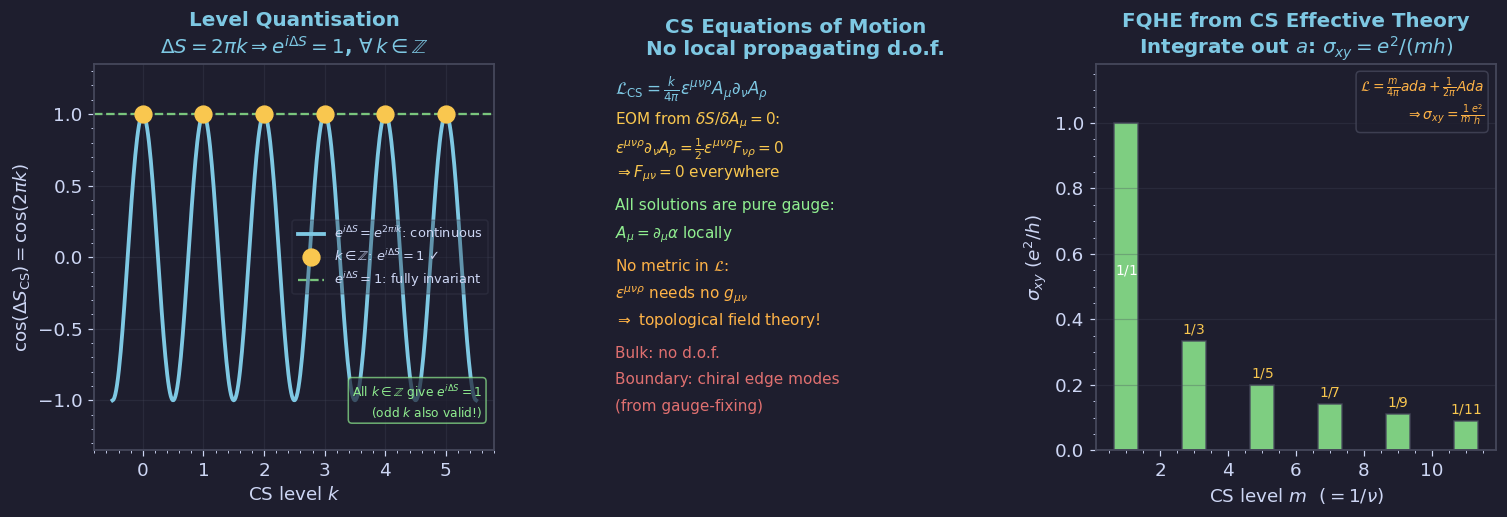

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch05'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01 · Chern-Simons Theory: Level Quantisation & Equations of Motion ─
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: CS gauge invariance — e^{i Delta S} = cos(pi k)
ax = axes[0]
# FIX: CS large gauge transformation gives ΔS=2πk → e^{iΔS}=e^{2πik}=1 for ALL k∈ℤ
# cos(2πk)=1 at every integer — both even AND odd k are gauge-invariant
# (Previous cos(πk) plot was misleading: showed -1 at odd k)
k_r = np.linspace(-0.5, 5.5, 400)
ax.plot(k_r, np.cos(2*np.pi*k_r), color=BLUE, lw=2.5,
        label=r'$e^{i\Delta S}=e^{2\pi ik}$: continuous')
k_int = np.arange(0, 6)
ax.scatter(k_int, np.ones_like(k_int), color=YELLOW, s=120, zorder=5,
           label=r'$k\in\mathbb{Z}$: $e^{i\Delta S}=1$ ✓')
ax.axhline(1, color=GREEN, lw=1.5, ls='--', alpha=0.8,
           label=r'$e^{i\Delta S}=1$: fully invariant')
ax.set_xlabel('CS level $k$')
ax.set_ylabel(r'$\cos(\Delta S_{\rm CS})=\cos(2\pi k)$')
ax.set_ylim(-1.35, 1.35)
ax.set_title('Level Quantisation\n'+
             r'$\Delta S=2\pi k\Rightarrow e^{i\Delta S}=1$, $\forall\,k\in\mathbb{Z}$',
             color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)
# 주석: 홀수 k도 완전히 gauge-invariant
ax.text(0.97, 0.08,
        r'All $k\in\mathbb{Z}$ give $e^{i\Delta S}=1$'+
        '\n(odd $k$ also valid!)',
        transform=ax.transAxes, ha='right', va='bottom',
        color=GREEN, fontsize=8,
        bbox=dict(boxstyle='round', facecolor=BG, edgecolor=GREEN, alpha=0.7))

# Middle: CS EOM — F=0 (flat connection), no local d.o.f.
ax2 = axes[1]
ax2.set_xlim(0,1); ax2.set_ylim(0,1); ax2.axis('off')
ax2.set_title('CS Equations of Motion\nNo local propagating d.o.f.', color=BLUE)
items = [
    (r'$\mathcal{L}_{\rm CS}=\frac{k}{4\pi}\varepsilon^{\mu\nu\rho}A_\mu\partial_\nu A_\rho$',
     BLUE, 11),
    ('', FG, 8),
    ('EOM from $\\delta S/\\delta A_\\mu=0$:', YELLOW, 10),
    (r'$\varepsilon^{\mu\nu\rho}\partial_\nu A_\rho = \frac{1}{2}\varepsilon^{\mu\nu\rho}F_{\nu\rho}=0$',
     YELLOW, 10),
    (r'$\Rightarrow F_{\mu\nu}=0$ everywhere', YELLOW, 10),
    ('', FG, 8),
    ('All solutions are pure gauge:', GREEN, 10),
    (r'$A_\mu=\partial_\mu\alpha$ locally', GREEN, 10),
    ('', FG, 8),
    ('No metric in $\\mathcal{L}$:', ORANGE, 10),
    (r'$\varepsilon^{\mu\nu\rho}$ needs no $g_{\mu\nu}$', ORANGE, 10),
    (r'$\Rightarrow$ topological field theory!', ORANGE, 10),
    ('', FG, 8),
    ('Bulk: no d.o.f.', RED, 10),
    ('Boundary: chiral edge modes', RED, 10),
    (r'(from gauge-fixing)', RED, 10),
]
y0 = 0.97
for txt, col, fs in items:
    ax2.text(0.05, y0, txt, transform=ax2.transAxes,
             color=col, fontsize=fs, va='top')
    y0 -= 0.068 if txt else 0.022

# Right: CS statistical interaction — sigma_xy from EOM
ax3 = axes[2]
m_list = np.arange(1,12,2)
sig = 1.0 / m_list
bars = ax3.bar(m_list, sig, color=GREEN, alpha=0.85, edgecolor=EDGE, width=0.7)
for m, s in zip(m_list, sig):
    if m == 1:  # 최상단 막대: 라벨을 막대 안쪽에
        ax3.text(m, s*0.55, f'$1/{m}$', ha='center', va='center',
                 color='white', fontsize=9, fontweight='bold')
    else:
        ax3.text(m, s+0.012, f'$1/{m}$', ha='center', va='bottom',
                 color=YELLOW, fontsize=9)
ax3.set_ylim(0, 1.18)  # 상단 여유 확보
ax3.set_xlabel('CS level $m$  $(= 1/\\nu)$')
ax3.set_ylabel(r'$\sigma_{xy}$ $(e^2/h)$')
ax3.set_title('FQHE from CS Effective Theory\n'+
              r'Integrate out $a$: $\sigma_{xy}=e^2/(mh)$', color=BLUE)
ax3.grid(True, axis='y')
ax3.text(0.97, 0.97,
         r'$\mathcal{L}=\frac{m}{4\pi}ada+\frac{1}{2\pi}Ada$' + '\n' +
         r'$\Rightarrow \sigma_{xy}=\frac{1}{m}\frac{e^2}{h}$',
         transform=ax3.transAxes, ha='right', va='top',
         color=ORANGE, fontsize=9,
         bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.8))

plt.tight_layout(pad=1.5)
save('fig01_cs_basics.png', fig)


---
## fig02 · FQHE Effective Theory & $K$-Matrix (§5.2)

**Left**: Flux attachment via CS — statistical transmutation  
**Middle**: $K$-matrix GSD on torus $|\det K|$ for various QH states  
**Right**: $\sigma_{xy}=(K^{-1})_{IJ}t^It^J\,e^2/h$ for key fractions

  saved -> figures/ch05/fig02_kmatrix.png


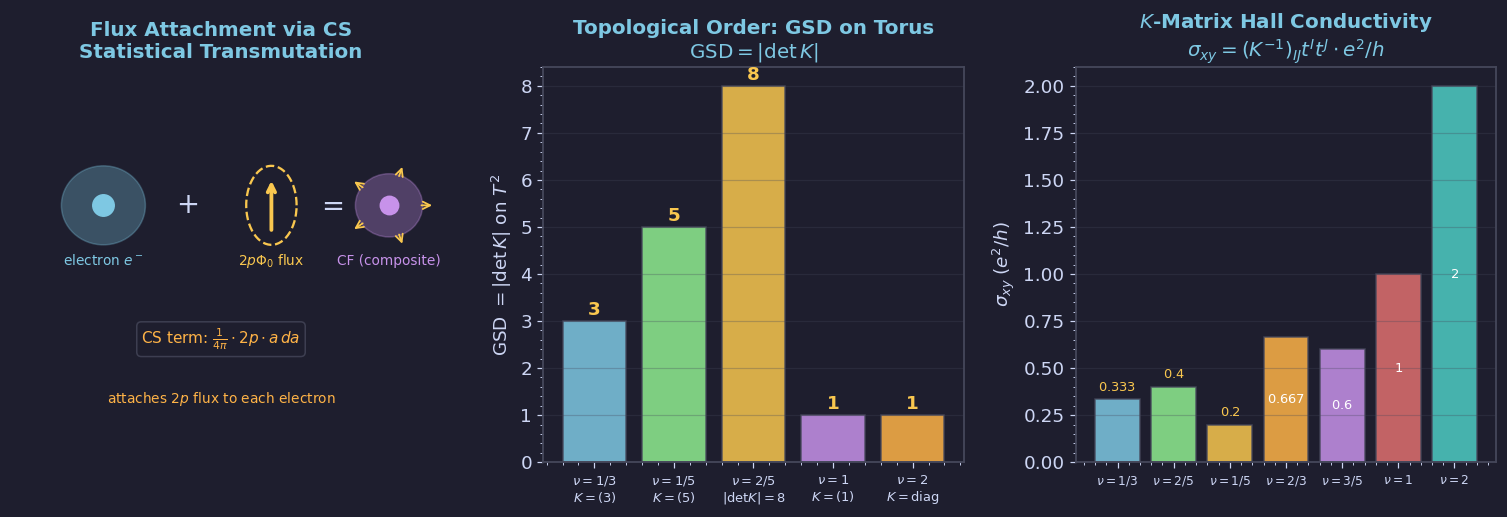

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch05'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02 · FQHE Effective Theory & K-Matrix ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Statistical transmutation — flux attachment via CS
ax = axes[0]
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
ax.set_title('Flux Attachment via CS\nStatistical Transmutation', color=BLUE)
# Draw electron + flux tube = composite fermion
# Electron circle
circ_e = plt.Circle((0.22, 0.65), 0.10, color=BLUE, alpha=0.3)
ax.add_patch(circ_e)
ax.plot(0.22, 0.65, 'o', color=BLUE, ms=14, zorder=5)
ax.text(0.22, 0.50, r'electron $e^-$', ha='center', color=BLUE, fontsize=9,
        transform=ax.transAxes)
# Plus sign
ax.text(0.42, 0.65, r'$+$', ha='center', va='center', color=FG, fontsize=18,
        transform=ax.transAxes)
# Flux tube
ax.annotate('', xy=(0.62, 0.72), xytext=(0.62, 0.58),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.5),
            xycoords='axes fraction', textcoords='axes fraction')
t_circ = np.linspace(0, 2*np.pi, 60)
ax.plot(0.62 + 0.06*np.cos(t_circ), 0.65 + 0.10*np.sin(t_circ),
        color=YELLOW, lw=1.5, ls='--', transform=ax.transAxes)
ax.text(0.62, 0.50, r'$2p\Phi_0$ flux', ha='center', color=YELLOW, fontsize=9,
        transform=ax.transAxes)
# Equals sign
ax.text(0.76, 0.65, r'$=$', ha='center', va='center', color=FG, fontsize=18,
        transform=ax.transAxes)
# Composite fermion
circ_cf = plt.Circle((0.90, 0.65), 0.08, color=PURPLE, alpha=0.3)
ax.add_patch(circ_cf)
ax.plot(0.90, 0.65, 'o', color=PURPLE, ms=12, zorder=5, transform=ax.transAxes)
# Flux lines around CF
for theta in np.linspace(0, 2*np.pi, 5, endpoint=False):
    r_cf = 0.11
    ax.annotate('', xy=(0.90+r_cf*np.cos(theta), 0.65+r_cf*np.sin(theta)),
                xytext=(0.90+(r_cf-0.04)*np.cos(theta),
                        0.65+(r_cf-0.04)*np.sin(theta)),
                arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2),
                xycoords='axes fraction', textcoords='axes fraction')
ax.text(0.90, 0.50, r'CF (composite)', ha='center', color=PURPLE, fontsize=9,
        transform=ax.transAxes)
# CS Lagrangian
ax.text(0.50, 0.30,
        r'CS term: $\frac{1}{4\pi}\cdot 2p\cdot a\,da$',
        ha='center', color=ORANGE, fontsize=10, transform=ax.transAxes,
        bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.8))
ax.text(0.50, 0.15,
        r'attaches $2p$ flux to each electron',
        ha='center', color=ORANGE, fontsize=9, transform=ax.transAxes)

# Middle: K-matrix GSD on torus
ax2 = axes[1]
states = [
    (r'$\nu=1/3$'   + '\n' + r'$K=(3)$',     3,  BLUE),
    (r'$\nu=1/5$'   + '\n' + r'$K=(5)$',     5,  GREEN),
    # K=[[3,1],[1,3]] for Halperin 331 state: det=8 ✓, GSD=8 ✓
    # Note: σ_xy=(K^{-1})tt = 1/2 ≠ 2/5; for Jain ν=2/5 the K-matrix
    # with correct σ_xy is more complex (multi-component hierarchy)
    (r'$\nu=2/5$'   + '\n' + r'$|{\rm det}K|=8$', 8, YELLOW),
    (r'$\nu=1$'     + '\n' + r'$K=(1)$',     1,  PURPLE),
    (r'$\nu=2$'     + '\n' + r'$K={\rm diag}$', 1, ORANGE),
]
xp = np.arange(len(states))
for xi, (lab, gsd, col) in enumerate(states):
    ax2.bar(xi, gsd, color=col, alpha=0.85, edgecolor=EDGE)
    ax2.text(xi, gsd+0.05, str(gsd), ha='center', va='bottom',
             color=YELLOW, fontsize=12, fontweight='bold')
ax2.set_xticks(xp)
ax2.set_xticklabels([s[0] for s in states], fontsize=8.5)
ax2.set_ylabel(r'GSD $=|\det K|$ on $T^2$')
ax2.set_title('Topological Order: GSD on Torus\n'+r'${\rm GSD}=|\det K|$', color=BLUE)
ax2.grid(True, axis='y')

# Right: sigma_xy from K-matrix for various states
ax3 = axes[2]
fracs_k = [
    (r'$\nu=1/3$',  1/3,  BLUE),
    (r'$\nu=2/5$',  2/5,  GREEN),
    (r'$\nu=1/5$',  1/5,  YELLOW),
    (r'$\nu=2/3$',  2/3,  ORANGE),
    (r'$\nu=3/5$',  3/5,  PURPLE),
    (r'$\nu=1$',    1.0,  RED),
    (r'$\nu=2$',    2.0,  '#4ecdc4'),
]
xf = np.arange(len(fracs_k))
for xi, (lab, nu_f, col) in enumerate(fracs_k):
    ax3.bar(xi, nu_f, color=col, alpha=0.85, edgecolor=EDGE)
    if nu_f >= 0.5:   # 높은 막대: 안쪽 중앙에 white
        ax3.text(xi, nu_f*0.5, f'${nu_f:.3g}$', ha='center', va='center',
                 color='white', fontsize=8.5, fontweight='bold')
    else:             # 낮은 막대: 위쪽에 YELLOW
        ax3.text(xi, nu_f+0.03, f'${nu_f:.3g}$', ha='center', va='bottom',
                 color=YELLOW, fontsize=8.5)
ax3.set_xticks(xf)
ax3.set_xticklabels([f[0] for f in fracs_k], fontsize=8)
ax3.set_ylabel(r'$\sigma_{xy}\;(e^2/h)$')
ax3.set_title('$K$-Matrix Hall Conductivity\n'+
              r'$\sigma_{xy}=(K^{-1})_{IJ}t^It^J\cdot e^2/h$', color=BLUE)
ax3.grid(True, axis='y')

plt.tight_layout(pad=1.5)
save('fig02_kmatrix.png', fig)


---
## fig03 · Particle-Vortex Duality & HLR State (§5.3)

**Left**: Particle-vortex duality — XY model $\leftrightarrow$ Abelian-Higgs via CS  
**Middle**: HLR CF Fermi sea at $\nu=1/2$ — compressible, $B^*=0$  
**Right**: Shubnikov-de Haas oscillations in $B^*=B-B_{1/2}$ confirming CFs

  saved -> figures/ch05/fig03_pvduality_hlr.png


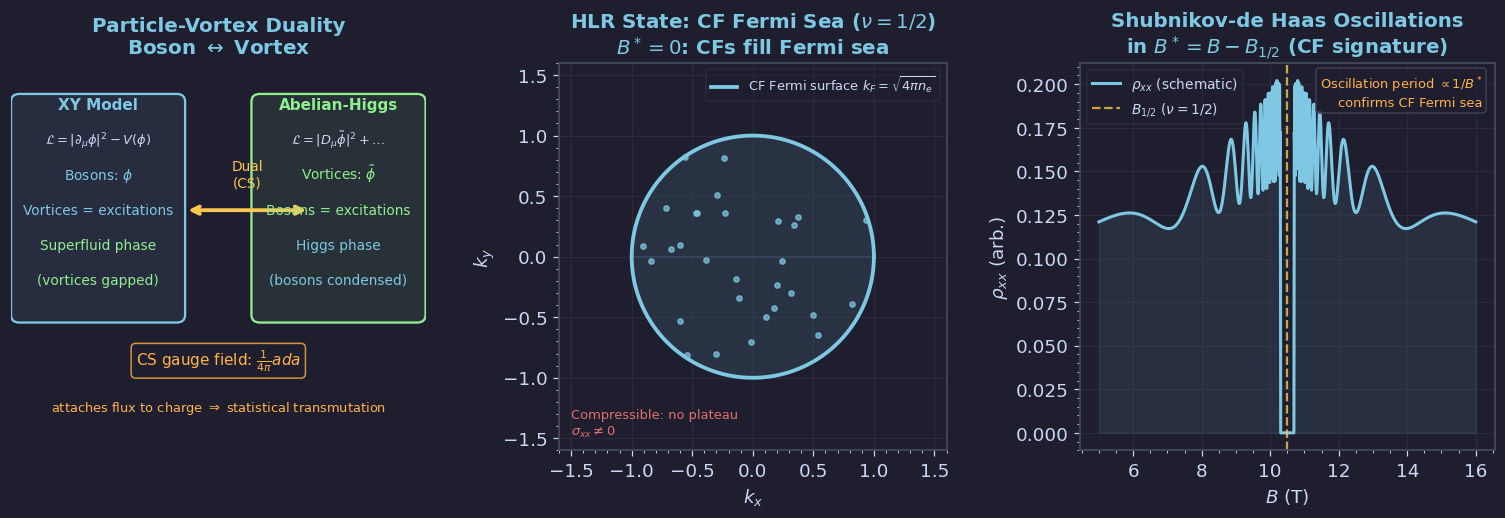

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch05'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03 · Particle-Vortex Duality & HLR State ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Particle-vortex duality schematic
ax = axes[0]
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
ax.set_title('Particle-Vortex Duality\n'+r'Boson $\leftrightarrow$ Vortex', color=BLUE)
# Left side: XY model (bosons)
ax.add_patch(FancyBboxPatch((0.02, 0.35), 0.38, 0.55,
             boxstyle='round,pad=0.02', facecolor=BLUE+'18', edgecolor=BLUE, lw=1.5))
ax.text(0.21, 0.88, 'XY Model', ha='center', color=BLUE, fontsize=10,
        fontweight='bold', transform=ax.transAxes)
ax.text(0.21, 0.79, r'$\mathcal{L}=|\partial_\mu\phi|^2-V(\phi)$',
        ha='center', color=FG, fontsize=8.5, transform=ax.transAxes)
ax.text(0.21, 0.70, r'Bosons: $\phi$',
        ha='center', color=BLUE, fontsize=9, transform=ax.transAxes)
ax.text(0.21, 0.61, r'Vortices = excitations',
        ha='center', color=BLUE, fontsize=9, transform=ax.transAxes)
ax.text(0.21, 0.52, r'Superfluid phase',
        ha='center', color=GREEN, fontsize=9, transform=ax.transAxes)
ax.text(0.21, 0.43, r'(vortices gapped)',
        ha='center', color=GREEN, fontsize=9, transform=ax.transAxes)
# Duality arrow
ax.annotate('', xy=(0.72, 0.62), xytext=(0.42, 0.62),
            arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=2.5),
            xycoords='axes fraction', textcoords='axes fraction')
ax.text(0.57, 0.68, 'Dual\n(CS)', ha='center', color=YELLOW, fontsize=9,
        transform=ax.transAxes)
# Right side: Abelian-Higgs model (vortices as particles)
ax.add_patch(FancyBboxPatch((0.60, 0.35), 0.38, 0.55,
             boxstyle='round,pad=0.02', facecolor=GREEN+'18', edgecolor=GREEN, lw=1.5))
ax.text(0.79, 0.88, 'Abelian-Higgs', ha='center', color=GREEN, fontsize=10,
        fontweight='bold', transform=ax.transAxes)
ax.text(0.79, 0.79, r'$\mathcal{L}=|D_\mu\tilde\phi|^2+\ldots$',
        ha='center', color=FG, fontsize=8.5, transform=ax.transAxes)
ax.text(0.79, 0.70, r'Vortices: $\tilde\phi$',
        ha='center', color=GREEN, fontsize=9, transform=ax.transAxes)
ax.text(0.79, 0.61, r'Bosons = excitations',
        ha='center', color=GREEN, fontsize=9, transform=ax.transAxes)
ax.text(0.79, 0.52, r'Higgs phase',
        ha='center', color=BLUE, fontsize=9, transform=ax.transAxes)
ax.text(0.79, 0.43, r'(bosons condensed)',
        ha='center', color=BLUE, fontsize=9, transform=ax.transAxes)
# CS at bottom
ax.text(0.50, 0.22,
        r'CS gauge field: $\frac{1}{4\pi}ada$',
        ha='center', color=ORANGE, fontsize=10, transform=ax.transAxes,
        bbox=dict(boxstyle='round', facecolor=BG, edgecolor=ORANGE, alpha=0.8))
ax.text(0.50, 0.10,
        r'attaches flux to charge $\Rightarrow$ statistical transmutation',
        ha='center', color=ORANGE, fontsize=8.5, transform=ax.transAxes)

# Middle: HLR state at nu=1/2 — CF Fermi sea
ax2 = axes[1]
theta_fs = np.linspace(0, 2*np.pi, 200)
k_F = 1.0
ax2.plot(k_F*np.cos(theta_fs), k_F*np.sin(theta_fs),
         color=BLUE, lw=2.5, label=r'CF Fermi surface $k_F=\sqrt{4\pi n_e}$')
ax2.fill_between(k_F*np.cos(theta_fs), k_F*np.sin(theta_fs),
                 alpha=0.12, color=BLUE)
np.random.seed(42)
kx_f = np.random.randn(60); ky_f = np.random.randn(60)
r_f  = np.sqrt(kx_f**2+ky_f**2)
mask = r_f < k_F
ax2.scatter(kx_f[mask], ky_f[mask], color=BLUE, s=12, alpha=0.7, zorder=4)
ax2.set_aspect('equal')
ax2.set_xlabel(r'$k_x$'); ax2.set_ylabel(r'$k_y$')
ax2.set_title(r'HLR State: CF Fermi Sea ($\nu=1/2$)'+'\n'+
              r'$B^*=0$: CFs fill Fermi sea', color=BLUE)
ax2.legend(fontsize=8.5, labelcolor=FG, loc='upper right')
ax2.grid(True); ax2.set_xlim(-1.6,1.6); ax2.set_ylim(-1.6,1.6)
ax2.text(0.03, 0.03, r'Compressible: no plateau' + '\n' + r'$\sigma_{xx}\neq0$',
         transform=ax2.transAxes, color=RED, fontsize=8.5, va='bottom')

# Right: SdH oscillations in B* = B - B_{1/2}
ax3 = axes[2]
# FIX: n2d adjusted so B_{ν=1/2} = B_half
# ν=1/2 → B_half = n·h/(ν·e) → n = ν·e·B_half/h
B_half = 10.5   # T at ν=1/2 (chosen for plot range)
import scipy.constants as sc_
_e, _h = 1.6e-19, 6.626e-34
n2d = 0.5 * _e * B_half / _h   # = 1.268e15 m^-2 ≈ 1.27e11 cm^-2
# Check: ν=1/2 at B=10.5T: B·e/(n·h) = 0.5 ✓
B = np.linspace(5, 16, 1000)
B_star = np.abs(B - B_half)
# SdH oscillations in rho_xx as function of 1/B*
osc = 1 + 0.4*np.cos(2*np.pi * n2d * 4.136e-15 / (B_star+0.1))
osc_envelope = np.exp(-0.3*B_star)
rho_xx = (0.1 + 0.08*osc*osc_envelope) * (B_star > 0.2)
rho_xx[B_star < 0.2] = 0.0
ax3.plot(B, rho_xx, color=BLUE, lw=2.0, label=r'$\rho_{xx}$ (schematic)')
ax3.axvline(B_half, color=YELLOW, lw=1.5, ls='--', alpha=0.8,
            label=r'$B_{1/2}$ ($\nu=1/2$)')
ax3.fill_between(B, rho_xx, alpha=0.1, color=BLUE)
ax3.set_xlabel('$B$ (T)')
ax3.set_ylabel(r'$\rho_{xx}$ (arb.)')
ax3.set_title('Shubnikov-de Haas Oscillations\n'+
              r'in $B^*=B-B_{1/2}$ (CF signature)', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True)
ax3.text(0.97, 0.97,
         r'Oscillation period $\propto 1/B^*$' + '\n' + r'confirms CF Fermi sea',
         transform=ax3.transAxes, ha='right', va='top',
         color=ORANGE, fontsize=8.5,
         bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.8))

plt.tight_layout(pad=1.5)
save('fig03_pvduality_hlr.png', fig)


---
## fig04 · Non-Abelian CS & CS on Torus (§5.4–5.5)

**Left**: Non-Abelian CS — Wilson loops, Jones polynomial, WZW boundary  
**Middle**: CS on $T^2$ — non-commuting Wilson loops $W_xW_y=e^{2\pi i/k}W_yW_x$  
**Right**: GSD $=k$ ($U(1)_k$) and $k+1$ ($SU(2)_k$) on torus

  saved -> figures/ch05/fig04_nonabelian_cs.png


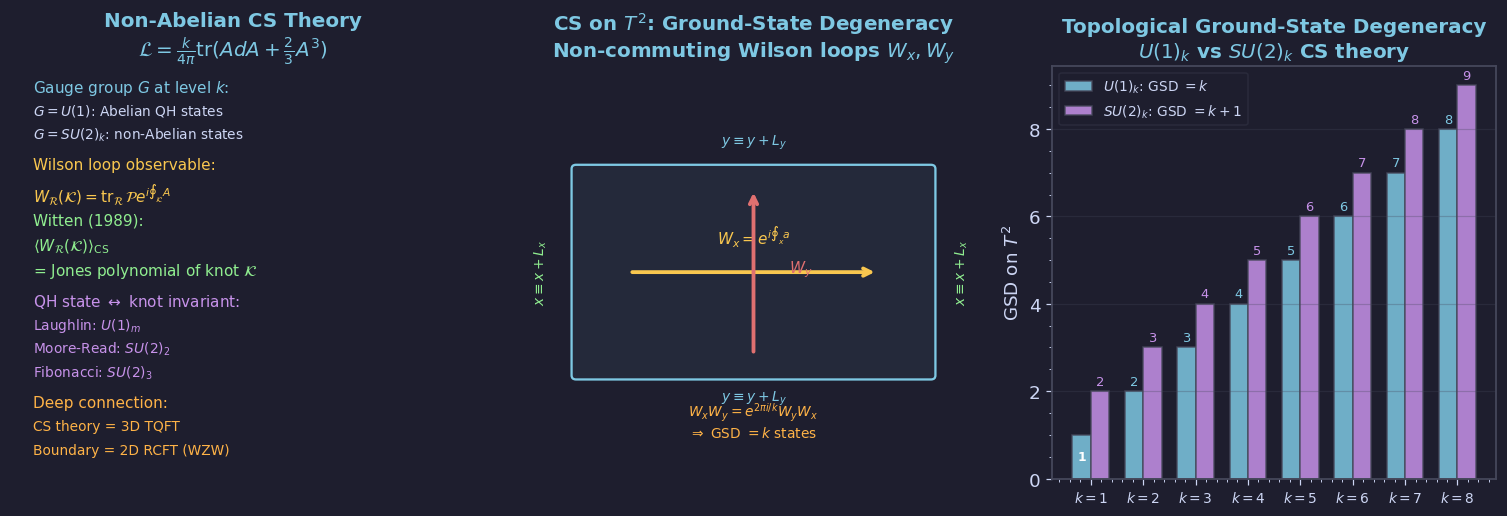

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch05'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04 · Non-Abelian CS Theory & CS on Torus ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Wilson loop expectation values — knot invariants
ax = axes[0]
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
ax.set_title('Non-Abelian CS Theory\n'+
             r'$\mathcal{L}=\frac{k}{4\pi}{\rm tr}(AdA+\frac{2}{3}A^3)$', color=BLUE)
items = [
    ('Gauge group $G$ at level $k$:', BLUE, 10),
    (r'$G=U(1)$: Abelian QH states', FG, 9),
    (r'$G=SU(2)_k$: non-Abelian states', FG, 9),
    ('', FG, 8),
    ('Wilson loop observable:', YELLOW, 10),
    (r'$W_\mathcal{R}(\mathcal{K})={\rm tr}_\mathcal{R}\,\mathcal{P}e^{i\oint_\mathcal{K}A}$',
     YELLOW, 10),
    ('', FG, 8),
    ('Witten (1989):', GREEN, 10),
    (r'$\langle W_\mathcal{R}(\mathcal{K})\rangle_{\rm CS}$', GREEN, 10),
    (r'= Jones polynomial of knot $\mathcal{K}$', GREEN, 10),
    ('', FG, 8),
    (r'QH state $\leftrightarrow$ knot invariant:', PURPLE, 10),
    (r'Laughlin: $U(1)_m$', PURPLE, 9),
    (r'Moore-Read: $SU(2)_2$', PURPLE, 9),
    (r'Fibonacci: $SU(2)_3$', PURPLE, 9),
    ('', FG, 8),
    ('Deep connection:', ORANGE, 10),
    ('CS theory = 3D TQFT', ORANGE, 9),
    ('Boundary = 2D RCFT (WZW)', ORANGE, 9),
]
y0 = 0.97
for txt, col, fs in items:
    ax.text(0.05, y0, txt, transform=ax.transAxes,
            color=col, fontsize=fs, va='top')
    y0 -= 0.058 if txt else 0.018

# Middle: CS on torus — non-commuting Wilson loops, GSD = k
ax2 = axes[1]
ax2.set_xlim(0,1); ax2.set_ylim(0,1); ax2.axis('off')
ax2.set_title(r'CS on $T^2$: Ground-State Degeneracy'+'\n'+
              r'Non-commuting Wilson loops $W_x, W_y$', color=BLUE)
# Draw torus schematically as a rectangle with identifications
torus_rect = FancyBboxPatch((0.10, 0.25), 0.80, 0.50,
                             boxstyle='round,pad=0.01',
                             facecolor=BLUE+'11', edgecolor=BLUE, lw=1.5)
ax2.add_patch(torus_rect)
ax2.text(0.50, 0.81, r'$y\equiv y+L_y$', ha='center', color=BLUE,
         fontsize=9, transform=ax2.transAxes)
ax2.text(0.50, 0.19, r'$y\equiv y+L_y$', ha='center', color=BLUE,
         fontsize=9, transform=ax2.transAxes)
ax2.text(0.02, 0.50, r'$x\equiv x+L_x$', ha='center', color=GREEN,
         fontsize=9, transform=ax2.transAxes, rotation=90, va='center')
ax2.text(0.97, 0.50, r'$x\equiv x+L_x$', ha='center', color=GREEN,
         fontsize=9, transform=ax2.transAxes, rotation=90, va='center')
# Wilson loop Wx: horizontal
ax2.annotate('', xy=(0.78, 0.50), xytext=(0.22, 0.50),
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.5),
             xycoords='axes fraction', textcoords='axes fraction')
ax2.text(0.50, 0.57, r'$W_x=e^{i\oint_x a}$', ha='center', color=YELLOW,
         fontsize=10, transform=ax2.transAxes)
# Wilson loop Wy: vertical
ax2.annotate('', xy=(0.50, 0.70), xytext=(0.50, 0.30),
             arrowprops=dict(arrowstyle='->', color=RED, lw=2.5),
             xycoords='axes fraction', textcoords='axes fraction')
ax2.text(0.58, 0.50, r'$W_y$', ha='left', color=RED,
         fontsize=10, transform=ax2.transAxes)
ax2.text(0.50, 0.10,
         r'$W_xW_y=e^{2\pi i/k}W_yW_x$' + '\n' + r'$\Rightarrow$ GSD $=k$ states',
         ha='center', color=ORANGE, fontsize=9, transform=ax2.transAxes)

# Right: GSD vs CS level k for U(1) and SU(2) theories
ax3 = axes[2]
k_arr = np.arange(1, 9)
gsd_u1  = k_arr          # U(1)_k: GSD = k on T^2
gsd_su2 = k_arr + 1      # SU(2)_k: GSD = k+1 on T^2
x = np.arange(len(k_arr)); w=0.35
ax3.bar(x-w/2, gsd_u1,  width=w, color=BLUE,   alpha=0.85, edgecolor=EDGE,
        label=r'$U(1)_k$: GSD $=k$')
ax3.bar(x+w/2, gsd_su2, width=w, color=PURPLE, alpha=0.85, edgecolor=EDGE,
        label=r'$SU(2)_k$: GSD $=k+1$')
ax3.set_xticks(x)
ax3.set_xticklabels([f'$k={ki}$' for ki in k_arr], fontsize=9)
ax3.set_ylabel(r'GSD on $T^2$')
ax3.set_title('Topological Ground-State Degeneracy\n'+
              r'$U(1)_k$ vs $SU(2)_k$ CS theory', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True, axis='y')
for xi, (gu, gs) in enumerate(zip(gsd_u1, gsd_su2)):
    # U(1): k=1 막대(GSD=1) 안쪽(white), 나머지 위쪽(BLUE)
    if gu <= 1:
        ax3.text(xi-w/2, gu*0.5, str(gu), ha='center', va='center',
                 color='white', fontsize=8, fontweight='bold')
    else:
        ax3.text(xi-w/2, gu+0.08, str(gu), ha='center', va='bottom',
                 color=BLUE, fontsize=8.5)
    # SU(2): 항상 위쪽(PURPLE)
    ax3.text(xi+w/2, gs+0.08, str(gs), ha='center', va='bottom',
             color=PURPLE, fontsize=8.5)

plt.tight_layout(pad=1.5)
save('fig04_nonabelian_cs.png', fig)


---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

zip_path = 'qhe_ch05_figures.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    for fname in sorted(os.listdir('figures/ch05')):
        fpath = os.path.join('figures/ch05', fname)
        zf.write(fpath, fname)
        print(f'  added {fname}')
print(f'\nCreated: {zip_path}')
files.download(zip_path)


  added fig01_cs_basics.png
  added fig02_kmatrix.png
  added fig03_pvduality_hlr.png
  added fig04_nonabelian_cs.png

Created: qhe_ch05_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>